# 05 — Protocol v1.0, Stage 2B: does text help a weak register?

**The scenario.** The register has no return-based lags: only IRS codes, state, and the BMF income and
asset amounts and codes. This is tier F0. Real cases are new registrants, units without tax accounts,
990-N filers and non-charity NPOs on a business-register-only frame. The design follows the tier:
**D1-W** stratifies NTEE10 × 3 BMF-income classes plus a take-all of the top 1% on BMF income.

**Hypotheses (protocol §9.4, secondary)**
- **S2, text helps a weak register.** GM over R ∪ H_D of RE(`MCAL_bmfmax@F0+E*` ∣ `MCAL_bmfmax@F0`) must reach point ≥ 1.20 with lower bound ≥ 1.10.
- **S2b, text substitutes for admin data.** The gap closure G = log RE(F0 + text ∣ F0) / log RE(F1p ∣ F0) is the share of the admin-lag gain that text recovers. G ≥ 0.5 means "substitutes".

**Variants (deviation D-28a)**
- **w** is exactly as pre-registered.
- **wprof** is a sensitivity. Under w, the 722 units with a zero BMF income amount (289 of them absent from the 2023-08 BMF; 6.7% of expenses, Harvard among them) sit in the bottom size classes. wprof emulates NSO profiling: the 206 largest units by frame lagged expenses get that as their design size, and take-all stays the top 1% on this combined size. That puts 171 of the 206 in take-all, every zero-BMF giant included, plus 35 units with large BMF income. Zero-BMF units left in take-some hold 0.4% of expenses.

**Text** is the same E* (TY2022 990 mission + programs). This is richer than BN registration text, so the setting favours text.

In [1]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PROJ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(PROJ, "src"))
DATA = os.environ.get("EMBAUX_DATA", "/tmp/claude-0/data")
import plotstyle; plotstyle.use()
from protocol import H_SET, H_D, H_S, R_SET, gm_re, verdict
from analysis import cell_metrics, paired_re
from report import Y_LABEL
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
RES = os.path.join(PROJ, "results", "stage2b_ne_v3"); os.makedirs(RES, exist_ok=True)
S2_Y = R_SET + H_D
runs = {}
for v in ["w", "wprof"]:
    p = f"{DATA}/results/stage2b_ne_v3_{v}"
    if os.path.exists(f"{p}/mc.parquet"):
        runs[v] = (pd.read_parquet(f"{p}/mc.parquet"), json.load(open(f"{p}/meta.json")))
        print(v, "R =", runs[v][1]["R"], "failures =", sum(runs[v][1]["failures"].values()))

w R = 1000 failures = 0
wprof R = 1000 failures = 0


## 1. The register defect behind D1-W

In [2]:
pop = pd.read_parquet(f"{DATA}/pop/ne_pop_v3.parquet")
z = pop.bmf_income_amt <= 0
miss = pop.bmf_income_cd.isna()
print(f"zero or missing BMF income amount: {z.sum()} units ({z.mean():.1%}); not in the 2023-08 BMF at all: {miss.sum()}")
print(f"their share of TY2023 expenses: {pop.y_expenses[z].sum() / pop.y_expenses.sum():.1%}; "
      f"of government grants: {pop.y_gov_grants[z].sum() / pop.y_gov_grants.sum():.1%}")
display(pop[z].nlargest(8, "lag_expenses")[["bmf_name", "lag_expenses", "bmf_income_amt", "bmf_income_cd", "bmf_subsection"]])
print("corr(log BMF income, log TY2023 revenue) =", round(np.corrcoef(np.log1p(pop.bmf_income_amt.clip(lower=0)), np.log1p(pop.y_revenue.clip(lower=0)))[0, 1], 3),
      "| corr(log TY2022 revenue, log TY2023 revenue) =", round(np.corrcoef(np.log1p(pop.lag_revenue.clip(lower=0)), np.log1p(pop.y_revenue.clip(lower=0)))[0, 1], 3))

zero or missing BMF income amount: 722 units (3.5%); not in the 2023-08 BMF at all: 289
their share of TY2023 expenses: 6.7%; of government grants: 6.2%


,bmf_name,lag_expenses,bmf_income_amt,bmf_income_cd,bmf_subsection
3774,PRESIDENT AND FELLOWS OF HARVARD COLLEGE,6.253074e+09,0.0,0.0,03
7283,BLUE CROSS BLUE SHIELD OF MASSACHUSETTS HMO BL...,5.325550e+09,0.0,NaN,NA
3522,NORTHEASTERN UNIVERSITY,2.460539e+09,0.0,0.0,03
3797,TRUSTEES OF TUFTS COLLEGE,1.323002e+09,0.0,0.0,03
3365,EMERSON COLLEGE,3.189806e+08,0.0,0.0,03
2319,NORTHERN NEW ENGLAND BENEFIT TRUST,2.191197e+08,0.0,NaN,NA
3916,DOUGLAS A THOM CLINIC INC,4.055669e+07,0.0,0.0,03
4333,MERRIMACK VALLEY CREDIT UNION,4.039056e+07,0.0,NaN,NA


corr(log BMF income, log TY2023 revenue) = 0.6 | corr(log TY2022 revenue, log TY2023 revenue) = 0.799


## 2. Validity: bias, coverage, negative control

In [3]:
for v, (df, meta) in runs.items():
    cm = cell_metrics(df, meta["truth"])
    arms = ["HT", "GREG_size_cat@F0", "MCAL_bmfmax@F0", "MCAL_bmfmax@F0+Estar", "MCAL_bmfmax@F0+N2perm", "GREG_size_cat@F1p", "MCAL_bmfmax@F1p"]
    sub = cm[cm.estimator.isin(arms)]
    for col, lab in [("rb_pct", "relative bias %"), ("coverage_pct", "95% CI coverage %"), ("rrmse_pct", "RRMSE %")]:
        t = sub.pivot(index="y", columns="estimator", values=col)[arms]; t.index = [Y_LABEL.get(i, i) for i in t.index]
        print(f"\n=== {v}: {lab} ==="); display(t.round(2))
    cm.to_csv(f"{RES}/cell_metrics_{v}.csv", index=False)
    re, lo, hi = zip(*[paired_re(df, meta["truth"], "MCAL_bmfmax@F0+N2perm", "MCAL_bmfmax@F0", y, B=500) for y in S2_Y + H_S])
    print(f"{v}: negative control N2perm vs twin, max upper bound over y = {max(hi):.3f} (gate: <= 1.03)")


=== w: relative bias % ===


estimator,HT,GREG_size_cat@F0,MCAL_bmfmax@F0,MCAL_bmfmax@F0+Estar,MCAL_bmfmax@F0+N2perm,GREG_size_cat@F1p,MCAL_bmfmax@F1p
Share with foreign activities,-1.17,-0.51,-0.37,-0.47,-0.37,5.72,5.74
Share granting to individuals,0.23,0.43,0.50,0.37,0.47,2.21,2.14
Share with gov. grants,-0.20,-0.25,-0.21,-0.11,-0.16,-0.18,-0.29
Share with volunteers,-0.28,-0.26,-0.25,-0.25,-0.24,-0.05,-0.09
Share lobbying,-0.09,0.06,0.08,0.08,0.09,3.96,3.64
Contributions,0.41,0.26,0.39,0.47,0.38,2.08,7.27
Employees,0.58,0.65,0.74,0.78,0.75,-0.21,-0.03
Total expenses,0.87,0.86,0.86,0.87,0.86,-0.15,-0.25
Fundraising expenses,1.71,2.41,2.29,2.51,2.47,-0.50,-3.07
Government grants,0.27,-0.65,0.01,0.07,-0.17,2.40,11.24



=== w: 95% CI coverage % ===


estimator,HT,GREG_size_cat@F0,MCAL_bmfmax@F0,MCAL_bmfmax@F0+Estar,MCAL_bmfmax@F0+N2perm,GREG_size_cat@F1p,MCAL_bmfmax@F1p
Share with foreign activities,90.2,90.5,90.6,90.2,90.7,91.3,90.9
Share granting to individuals,95.0,94.1,93.5,94.6,93.7,95.0,95.0
Share with gov. grants,94.2,93.8,92.9,93.4,93.1,93.6,92.6
Share with volunteers,95.6,95.4,95.3,95.5,95.5,95.3,95.0
Share lobbying,92.3,91.6,91.8,91.8,91.8,92.5,92.3
Contributions,71.5,69.6,67.9,66.0,67.3,73.0,47.0
Employees,69.3,61.5,58.0,54.0,58.2,87.0,78.6
Total expenses,28.9,12.8,12.8,12.6,12.7,75.7,61.6
Fundraising expenses,50.2,50.6,44.5,43.4,46.5,71.6,42.9
Government grants,78.5,76.3,75.0,74.2,74.9,73.3,62.6



=== w: RRMSE % ===


...


=== wprof: 95% CI coverage % ===


estimator,HT,GREG_size_cat@F0,MCAL_bmfmax@F0,MCAL_bmfmax@F0+Estar,MCAL_bmfmax@F0+N2perm,GREG_size_cat@F1p,MCAL_bmfmax@F1p
Share with foreign activities,90.1,91.3,91.2,91.2,91.1,90.3,90.1
Share granting to individuals,95.7,94.8,94.7,94.6,95.0,94.4,94.7
Share with gov. grants,95.2,94.3,94.5,94.8,94.4,94.1,94.6
Share with volunteers,96.1,94.9,95.5,94.9,95.1,95.0,95.0
Share lobbying,91.6,92.0,91.8,91.8,91.9,92.5,92.2
Contributions,92.1,91.2,90.1,90.0,90.0,88.6,89.4
Employees,93.9,92.3,91.8,91.1,90.8,90.5,88.4
Total expenses,94.3,93.0,93.6,93.3,93.2,89.6,88.5
Fundraising expenses,93.2,91.8,89.2,89.3,90.1,88.3,88.1
Government grants,89.2,88.3,88.3,88.5,87.6,86.5,86.3



=== wprof: RRMSE % ===


estimator,HT,GREG_size_cat@F0,MCAL_bmfmax@F0,MCAL_bmfmax@F0+Estar,MCAL_bmfmax@F0+N2perm,GREG_size_cat@F1p,MCAL_bmfmax@F1p
Share with foreign activities,14.56,14.46,14.54,14.43,14.54,14.46,14.52
Share granting to individuals,11.51,11.65,11.73,11.41,11.73,11.69,11.71
Share with gov. grants,6.97,6.95,6.85,6.68,6.86,6.95,6.80
Share with volunteers,4.07,4.09,4.08,4.04,4.09,4.10,4.06
Share lobbying,13.34,13.38,13.36,13.35,13.39,13.41,13.37
Contributions,4.62,4.12,3.81,3.70,3.78,4.45,3.91
Employees,3.85,3.28,3.12,2.93,3.17,1.52,1.54
Total expenses,2.30,1.00,0.99,1.00,1.00,0.82,0.82
Fundraising expenses,5.49,5.74,5.27,5.35,5.43,6.36,5.72
Government grants,11.26,10.49,10.07,10.18,10.06,11.06,10.37


wprof: negative control N2perm vs twin, max upper bound over y = 1.037 (gate: <= 1.03)


## 3. S2 and S2b

In [4]:
rows = []
for v, (df, meta) in runs.items():
    tr = meta["truth"]
    pairs = {"S2: F0 text vs F0 twin": ("MCAL_bmfmax@F0+Estar", "MCAL_bmfmax@F0"),
             "F0 twin vs F0 GREG (what ML on codes adds)": ("MCAL_bmfmax@F0", "GREG_size_cat@F0"),
             "F0 text vs F0 GREG": ("MCAL_bmfmax@F0+Estar", "GREG_size_cat@F0"),
             "F0 NTEE10-twin text increment": ("MCAL_frame@F0+Estar", "MCAL_frame@F0"),
             "F0 E* K=64": ("MCAL_bmfmax@F0+Estar64", "MCAL_bmfmax@F0"),
             "F0 MiniLM (L4)": ("MCAL_bmfmax@F0+L4", "MCAL_bmfmax@F0"),
             "F1p GREG vs F0 twin (what lags add)": ("GREG_size_cat@F1p", "MCAL_bmfmax@F0"),
             "F1p twin vs F0 twin (what lags add, ML)": ("MCAL_bmfmax@F1p", "MCAL_bmfmax@F0"),
             "F1p text vs F1p twin (P1 on D1-W samples)": ("MCAL_bmfmax@F1p+Estar", "MCAL_bmfmax@F1p")}
    for name, (a, b) in pairs.items():
        for lab, ys in [("R ∪ H_D", S2_Y), ("H", H_SET), ("R", R_SET), ("H_D", H_D)]:
            pt, lo, hi, per = gm_re(df, tr, a, b, ys)
            bar, anyg = verdict(pt, lo, hi)
            rows.append({"variant": v, "pair": name, "set": lab, "gm_re": pt, "lo95": lo, "hi95": hi, "any_gain": anyg,
                         "S2 bar (>=1.20, lo>=1.10)": ("MET" if (pt >= 1.20 and lo >= 1.10) else ("EXCLUDED" if hi < 1.20 else "OPEN")),
                         **{f"re:{k}": x for k, x in per.items()}})
S2 = pd.DataFrame(rows)
S2.to_csv(f"{RES}/s2_pairs.csv", index=False)
display(S2[S2.set == "R ∪ H_D"][["variant", "pair", "gm_re", "lo95", "hi95", "any_gain", "S2 bar (>=1.20, lo>=1.10)"]].round(3))

,variant,pair,gm_re,lo95,hi95,any_gain,"S2 bar (>=1.20, lo>=1.10)"
0,w,S2: F0 text vs F0 twin,1.000,0.999,1.002,NO,EXCLUDED
4,w,F0 twin vs F0 GREG (what ML on codes adds),1.002,1.000,1.005,YES,EXCLUDED
8,w,F0 text vs F0 GREG,1.002,0.999,1.006,NO,EXCLUDED
12,w,F0 NTEE10-twin text increment,1.004,1.002,1.006,YES,EXCLUDED
16,w,F0 E* K=64,1.000,0.999,1.002,NO,EXCLUDED
20,w,F0 MiniLM (L4),0.998,0.996,1.001,NO,EXCLUDED
24,w,F1p GREG vs F0 twin (what lags add),66.987,51.609,81.851,YES,MET
28,w,"F1p twin vs F0 twin (what lags add, ML)",17.261,13.166,21.758,YES,MET
32,w,F1p text vs F1p twin (P1 on D1-W samples),1.480,1.386,1.577,YES,MET
36,wprof,S2: F0 text vs F0 twin,1.035,1.022,1.047,YES,EXCLUDED


In [5]:
gap = []
for v in runs:
    t = S2[(S2.variant == v) & (S2.set == "R ∪ H_D")].set_index("pair")
    num = np.log(t.loc["S2: F0 text vs F0 twin", "gm_re"])
    for ref in ["F1p GREG vs F0 twin (what lags add)", "F1p twin vs F0 twin (what lags add, ML)"]:
        den = np.log(t.loc[ref, "gm_re"])
        gap.append({"variant": v, "F1p reference": ref.split(" vs")[0], "log RE text": num, "log RE lags": den, "gap closure G": num / den if den > 0 else np.nan})
gap = pd.DataFrame(gap); display(gap.round(3)); gap.to_csv(f"{RES}/s2b_gap_closure.csv", index=False)
for v in runs:
    g = gap[gap.variant == v]
    gbest = g.loc[g["log RE lags"].idxmax(), "gap closure G"]
    print(f"{v}: S2b gap closure against the better F1p reference = {gbest:.3f} -> {'substitutes (>= 0.5)' if gbest >= 0.5 else 'does not substitute (< 0.5)'}")

,variant,F1p reference,log RE text,log RE lags,gap closure G
0,w,F1p GREG,0.000,4.205,0.00
1,w,F1p twin,0.000,2.848,0.00
2,wprof,F1p GREG,0.034,0.262,0.13
3,wprof,F1p twin,0.034,0.338,0.10


w: S2b gap closure against the better F1p reference = 0.000 -> does not substitute (< 0.5)
wprof: S2b gap closure against the better F1p reference = 0.100 -> does not substitute (< 0.5)


### Per-variable RE of text in the weak register

In [6]:
per = S2[(S2.set == "R ∪ H_D") & S2.pair.isin(["S2: F0 text vs F0 twin", "F1p twin vs F0 twin (what lags add, ML)"])]
per = per.set_index(["variant", "pair"])[[f"re:{y}" for y in S2_Y]]
per.columns = [Y_LABEL.get(c[3:], c[3:]) for c in per.columns]
display(per.T.round(3))

variant                                      w                                                          wprof                                        
pair                    S2: F0 text vs F0 twin F1p twin vs F0 twin (what lags add, ML) S2: F0 text vs F0 twin F1p twin vs F0 twin (what lags add, ML)
Total revenue                            1.000                                 137.403                  0.990                                   1.582
Total expenses                           1.000                                 179.993                  0.993                                   1.460
Employees                                1.002                                  75.395                  1.140                                   4.108
Salaries                                 1.001                                 170.933                  1.111                                   2.543
Government grants                        1.003                                   1.021                  0.979                                   0.942
Contributions                            1.003                                   1.691                  1.058                                   0.949
Program service revenue                  0.999                                  71.106                  1.077                                   1.141
Fundraising expenses                     1.001                                  15.154                  0.972                                   0.850
Officer compensation                     0.992                                   0.230                  1.006                                   0.998

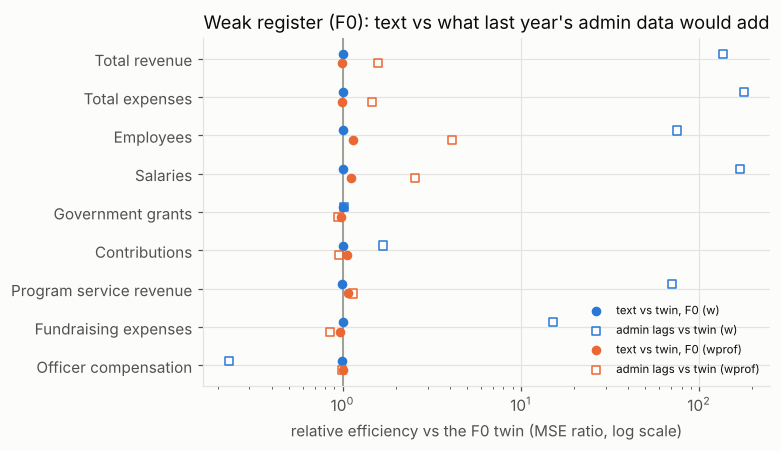

In [7]:
if runs:
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    labs = [Y_LABEL.get(y, y) for y in S2_Y]
    yy = np.arange(len(S2_Y))
    for j, v in enumerate(runs):
        r = S2[(S2.variant == v) & (S2.set == "R ∪ H_D") & (S2.pair == "S2: F0 text vs F0 twin")].iloc[0]
        ax.scatter([r[f"re:{y}"] for y in S2_Y], yy + (j - 0.5) * 0.25, s=28, color=plotstyle.SERIES[j], label=f"text vs twin, F0 ({v})", zorder=3)
        r2 = S2[(S2.variant == v) & (S2.set == "R ∪ H_D") & (S2.pair == "F1p twin vs F0 twin (what lags add, ML)")].iloc[0]
        ax.scatter([r2[f"re:{y}"] for y in S2_Y], yy + (j - 0.5) * 0.25, s=28, marker="s", facecolor="none", edgecolor=plotstyle.SERIES[j],
                   label=f"admin lags vs twin ({v})", zorder=3)
    ax.axvline(1, color=plotstyle.NEUTRAL, lw=1); ax.set_xscale("log")
    ax.set_yticks(yy); ax.set_yticklabels(labs); ax.invert_yaxis()
    ax.set_xlabel("relative efficiency vs the F0 twin (MSE ratio, log scale)")
    ax.set_title("Weak register (F0): text vs what last year's admin data would add")
    ax.legend(fontsize=7.5, loc="lower right")
    plt.tight_layout(); plt.savefig(f"{RES}/s2_weak_register.png", dpi=150); plt.show()